## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Adeline Kwakye

**Date:** 10/19/2026

[6, 30, 4, 2, 150, 28, 21, 4, 4, 389, 31, 1, 1, 85, 115, 78, 2, 22, 97, 95, 6, 11, 1, 22, 324, 41, 178, 373, 16, 82, 15, 1365, 58, 18, 3, 21, 1, 2, 501, 110, 8, 17, 7, 798, 22, 8, 125, 8, 9, 116, 93, 14, 14, 680, 14, 234, 229, 54, 1, 1, 10, 5, 3, 21, 34, 105, 67, 5, 229, 1, 166, 121, 176, 147, 63, 117, 95, 19, 90, 39, 24, 138, 8, 12, 79, 305, 12, 869, 1, 117, 11, 44, 32, 1052, 52, 3, 13, 609, 7, 17, 3, 166, 1, 1, 110, 2, 1, 2, 33, 172, 27, 2, 2, 3, 124, 17, 6, 2, 45, 2, 27, 5, 21, 32, 352, 651, 24, 221, 142, 85, 127, 138, 172, 14, 188, 79, 43, 7, 6, 68, 175, 98, 397, 178, 47, 45, 43, 403, 316, 8, 421, 1, 164, 1, 1022, 31, 239, 161, 305, 81, 251, 625, 1, 1202, 1, 1, 1, 41, 187, 83, 90, 71, 265, 1, 40, 109, 82, 8, 17, 523, 208, 10, 10, 92, 129, 93, 8, 239, 4, 10, 1, 55, 1, 7, 205, 27, 25, 28, 5, 6, 125, 160, 587, 2, 11, 383, 3, 312, 553, 1, 114, 24, 50, 14, 4, 52, 61, 6, 134, 287, 4, 89, 1, 10, 20, 4, 40, 18, 26, 1, 1, 1, 5, 1, 1, 8, 6, 3, 7, 12, 550, 39, 138, 26, 806, 923, 174, 191, 10,

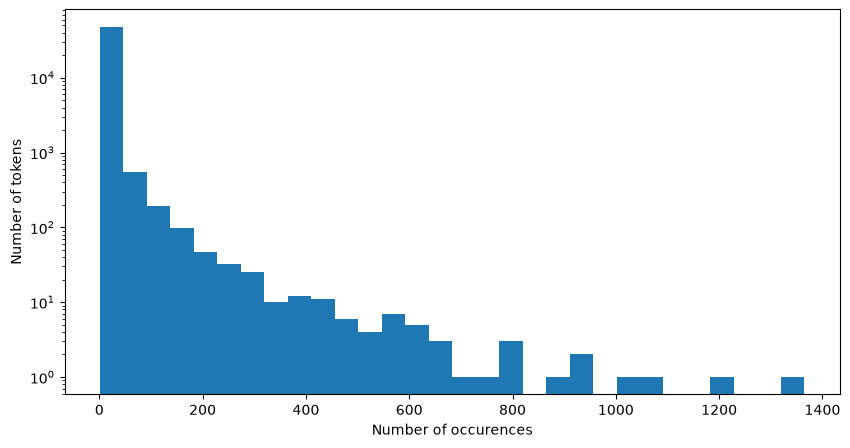

split data 80/20

Training test r-squared:  0.7678
Test r-squared:  0.6571

Top 10 token values 
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:    0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning              0.5150
#000000;             0.5029
dtype: float64

tokens that indicate scams vs safe
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:   -0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning             -0.5150
#000000;             0.5029
dtype: float64


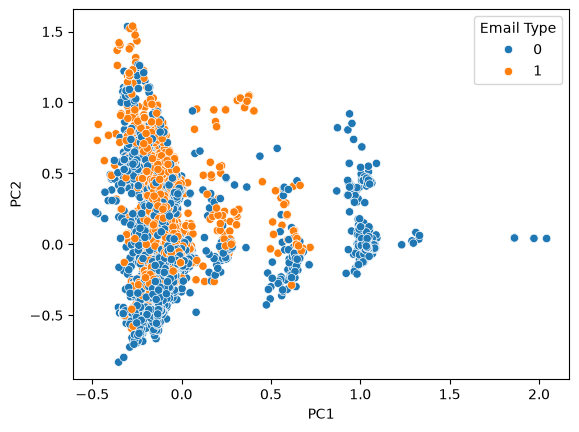

(14907, 2711)

Training pca shape:  (14907, 2610)

Test pca shape:  (3727, 2610)
PCA Regression Training test r-squared:  0.7669
PCA Regression Test r-squared:  0.6614


In [7]:
# Your Phase 1 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# listing out how often each token appears
token_values = list(token_count.values())
print(token_values)
# plot the distribution
plt.figure(figsize=(10,5))
plt.yscale('log')
plt.hist(token_values, bins=30)
plt.xlabel("Number of occurences")
plt.ylabel("Number of tokens")
plt.show()

# q2
df = pd.read_parquet('data/Phishing_clean.parquet')
# split data 80/20
print("split data 80/20\n")
X = df.drop(columns = ["Email Type"]) # features all columns except email type
y = df["Email Type"] # target email type

(X_train, X_valid, y_train, y_valid,) = train_test_split(X, y, test_size = 0.20, random_state = 65 )

# run linear regression on y
model = LinearRegression()
model.fit(X_train,y_train)
# evaluates r^2 on training and test sets
r2_train = model.score(X_train,y_train)
r2_valid = model.score(X_valid, y_valid)

print("Training test r-squared: ", round(r2_train, 4))
print("Test r-squared: ", round(r2_valid,4))

# find most influential tokens
coef_series = pd.Series(model.coef_, index=X_train.columns)
# top 10 tokens based on absolute value
top_tokens_absolute = coef_series.abs().sort_values(ascending=False).head(10)
print("\nTop 10 token values ")
print(top_tokens_absolute.round(4))
# to determine which words are scams vs safe
print("\ntokens that indicate scams vs safe")
print(coef_series.loc[top_tokens_absolute.index].round(4))


# q3

# fit pca with 2 dimensions
pca_2 = PCA(n_components = 2).fit(X)
X_pca_sklearn = pca_2.transform(X)

#put in df to help make scatter plot

pca_df = pd.DataFrame(X_pca_sklearn, columns =["PC1", "PC2"])
pca_df['Email Type'] = y.values
# scatter plot
sns.scatterplot(
    data = pca_df,
    x= "PC1",
    y="PC2",
    hue = "Email Type"
)
plt.show()


# q4
print(X_train.shape)
pca_regression = PCA(n_components=2610)
X_train_pca = pca_regression.fit_transform(X_train)
X_valid_pca = pca_regression.transform(X_valid)

print("\nTraining pca shape: ", X_train_pca.shape)
print("\nTest pca shape: ", X_valid_pca.shape)
# run linear regression
pca_regression_model = LinearRegression()
pca_regression_model.fit(X_train_pca,y_train)

pca_regression_r2_train = pca_regression_model.score(X_train_pca, y_train)
pca_regression_r2_valid = pca_regression_model.score(X_valid_pca, y_valid)

print("PCA Regression Training test r-squared: ", round(pca_regression_r2_train, 4))
print("PCA Regression Test r-squared: ", round(pca_regression_r2_valid,4))

Q1.
The histogram appears to be right-skewed. Prior to scaling the plot, almost all the data appeared to be compressed into the very first bar next to zero. After doing a logarithmic scale of the y-axis, the distribution shows that the number of unique tokens drops as occurences increases. The majority of unique tokens appear only a few times across the entire dataset and only a small amount of tokens occur repeatedly.

Q2.
The linear regression model had an R-squared of 0.7678 on the training data and 0.6571 on the test data. The higher training score suggests that the model fits the training data better as opposed to the unseen test data. The tokens that had the largest absolute coefficients were aging, helvetica, and localized. Aging had the largest coefficent in absolute value of 0.9965, meaning that it had the strongest influence on predictions. Other tokens also had large absolute value coefficients like helvitica with 0.8922, localized with 0.7879 and background-image with 0.7801. The absolute values show the magnitude of each coefficient. 

Q3.
The scatter plot shows a huge overlap between phising and legitimate emails, especially in the first main cluster. This shows that the first two principal components don't distinctly distinguish between the two kinds of emails. For The areas with higher PC1 values contain mostly legitimate emails, which lets us know that some pattersn in the data are more common in legitmate emails as opposed to phishing emails. 

Q4.
The principal component regression model had a training R^2 of 0.7669 and a test R^2 of 0.6614. Compared to the original linear regression model, which had a training R^2 of 0.7678 and a test R^2 of 0.6571, the performance was fairly similar. The principal comonent regression had a slightly lower training R^2, but a slightly higher test R^2, which suggests that it performed better on the test set.

Q5. 
An advantage of using principal components would be that they reduce the number of features in the dataset while at the same time retaining much of the variation. This allows for the regression to be more computationally manageable and reduce issues caused by the numerous features. In this case, the principal component responded fairly similar to the original linear regression, with a slightly higher test R^2.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]